<a href="https://colab.research.google.com/github/USERNAME/Grokking-Deep-Learning/blob/main/04_gradient-descent.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 4: Gradient Descent
## Teaching a network to reduce its own error

**Companion notebook for *Grokking Deep Learning* (Andrew W. Trask, Manning)**

This notebook walks through every code listing of Chapter 4 in order: *compare → hot and cold → gradient descent → divergence → alpha*. Extra plots (my own additions) show the error "bowl", the path the weight takes, and the effect of different alphas.

---
## Predict, compare, and learn

Chapter 3 covered **predict**. The open question was *how do we choose weights that predict well?* This chapter supplies the two missing steps:

| Step | Question it answers | Output |
|---|---|---|
| **Predict** | What does the network think? | a prediction |
| **Compare** | How badly did it miss? | an error number |
| **Learn** | How should each weight change? | a weight update |

---
## Compare

Comparing produces a single measurement of *how much the prediction missed by*. Designing a good error measure is one of the most important decisions in deep learning. Here we use **squared error**. Compare only says "big miss" or "small miss": a hot/cold signal. It does **not** say which way to move or why.

---
## Learn

Learning is **error attribution**: working out how much each weight contributed to the miss, then nudging every weight in the direction that shrinks it. The most popular method, and the focus of this chapter, is **gradient descent**. The end product is one number per weight: *"go up this much"* or *"go down this much"*.

---
## Compare: does your network make good predictions?

Let's measure an error. The code should print **0.3025**.

In [1]:
knob_weight = 0.5
input = 0.5
goal_pred = 0.8

pred = input * knob_weight
error = (pred - goal_pred) ** 2
print(error)

0.30250000000000005


- `goal_pred` is the true value, something you recorded but wouldn't normally know ahead of time (e.g. "did the batter hit a home run?").
- The prediction was 0.25, which misses by 0.55; squared, that is **0.3025**.
- **Why square it?** An archer who is 2 inches too high and one who is 2 inches too low both missed by 2 inches, so error must be *positive*. Squaring does that, and as a bonus it makes big misses count far more than tiny ones.

---
## Why measure error?

Two reasons:

1. **Simplicity**: "make the error zero" is a cleaner target than "make the prediction equal the goal".
2. **Priorities**: the shape of the error function decides which mistakes the network cares about. Squared error amplifies big misses and shrinks small ones. Absolute value would treat them proportionally.

It must also be positive. Otherwise, averaging over many examples can hide failures, e.g. misses of +1000 and −1000 average to a "perfect" 0.

In [2]:
for pure in [10, 0.01]:
    print(f"pure error {pure:>5}:  squared = {pure ** 2:<10}  absolute = {abs(pure)}")

print()
print("mean of raw errors     :", (1000 + (-1000)) / 2)            # looks perfect, but isn't!
print("mean of squared errors :", (1000 ** 2 + (-1000) ** 2) / 2)  # reveals the truth

pure error    10:  squared = 100         absolute = 10
pure error  0.01:  squared = 0.0001      absolute = 0.01

mean of raw errors     : 0.0
mean of squared errors : 1000000.0


---
## What's the simplest form of neural learning?

**Hot and cold learning**: wiggle the weight up and down, see which direction gives the smaller error, move that way, repeat. Learning becomes a *search* for the weight with the lowest error.

Here is one iteration (starting weight 0.1, step 0.01). *(The book's figure has a small typo in the final `if`; this version compares `e_dn` with `e_up` correctly.)*

In [3]:
weight = 0.1
lr = 0.01

def neural_network(input, weight):
    prediction = input * weight
    return prediction

number_of_toes = [8.5]
win_or_lose_binary = [1]   # the team won

input = number_of_toes[0]
true = win_or_lose_binary[0]

# PREDICT
pred = neural_network(input, weight)
error = (pred - true) ** 2
print("current error :", round(error, 4))

# COMPARE: try a higher and a lower weight
p_up = neural_network(input, weight + lr)
e_up = (p_up - true) ** 2
print("error if up   :", round(e_up, 4))

p_dn = neural_network(input, weight - lr)
e_dn = (p_dn - true) ** 2
print("error if down :", round(e_dn, 4))

# LEARN: move in the better direction
if error > e_dn or error > e_up:
    if e_dn < e_up:
        weight -= lr
    if e_up < e_dn:
        weight += lr
print("new weight    :", round(weight, 4))

current error : 0.0225
error if up   : 0.0042
error if down : 0.0552
new weight    : 0.11


Raising the weight lowered the error from 0.0225 to about 0.004; lowering it raised the error to about 0.055. So the weight moved **up**.

---
## Hot and cold learning (in a loop)

Now repeat that until the prediction hits the goal of 0.8. (To keep the notebook readable, only some iterations are printed.)

In [4]:
weight = 0.5
input = 0.5
goal_prediction = 0.8

step_amount = 0.001

for iteration in range(1101):
    prediction = input * weight
    error = (prediction - goal_prediction) ** 2

    if iteration < 3 or iteration % 200 == 0 or iteration == 1100:
        print(f"iter {iteration:4d}  error = {error:.10f}  prediction = {prediction:.4f}")

    up_prediction = input * (weight + step_amount)
    up_error = (goal_prediction - up_prediction) ** 2

    down_prediction = input * (weight - step_amount)
    down_error = (goal_prediction - down_prediction) ** 2

    if down_error < up_error:
        weight = weight - step_amount
    if down_error > up_error:
        weight = weight + step_amount

iter    0  error = 0.3025000000  prediction = 0.2500
iter    1  error = 0.3019502500  prediction = 0.2505
iter    2  error = 0.3014010000  prediction = 0.2510
iter  200  error = 0.2025000000  prediction = 0.3500
iter  400  error = 0.1225000000  prediction = 0.4500
iter  600  error = 0.0625000000  prediction = 0.5500
iter  800  error = 0.0225000000  prediction = 0.6500
iter 1000  error = 0.0025000000  prediction = 0.7500
iter 1100  error = 0.0000000000  prediction = 0.8000


---
## Characteristics of hot and cold learning

**Good:** it is simple and it does work.

**Bad, problem 1: it is slow.** Each weight update costs three predictions.

**Bad, problem 2: the step size is arbitrary.** The method finds the *direction* but guesses the *amount*. If the ideal weight isn't a multiple of the step, the weight will keep hopping back and forth over it. A huge step never settles at all. Try it:

In [5]:
def hot_cold(step_amount, iters=12):
    weight, input, goal = 0.5, 0.5, 0.8
    out = []
    for _ in range(iters):
        pred = input * weight
        out.append(round(pred, 3))
        up   = (goal - input * (weight + step_amount)) ** 2
        down = (goal - input * (weight - step_amount)) ** 2
        if down < up: weight -= step_amount
        if down > up: weight += step_amount
    return out

print("step 0.001:", hot_cold(0.001)[:6], "... (slow but steady)")
print("step 0.2  :", hot_cold(0.2))
print("step 10   :", hot_cold(10))

step 0.001: [0.25, 0.251, 0.251, 0.252, 0.252, 0.253] ... (slow but steady)
step 0.2  : [0.25, 0.35, 0.45, 0.55, 0.65, 0.75, 0.85, 0.75, 0.85, 0.75, 0.85, 0.75]
step 10   : [0.25, 5.25, 0.25, 5.25, 0.25, 5.25, 0.25, 5.25, 0.25, 5.25, 0.25, 5.25]


With step 0.2 the prediction creeps up, passes 0.8 and then oscillates 0.75 ↔ 0.85 forever. With step 10 it jumps 0.25 ↔ 5.25 and never gets close. We need *direction **and** amount* without repeated prediction.

---
## Calculating both direction and amount from error

Here is the improvement: compute the move straight from the error, with no wiggling:

In [6]:
weight = 0.5
goal_pred = 0.8
input = 0.5

for iteration in range(20):
    pred = input * weight
    error = (pred - goal_pred) ** 2
    direction_and_amount = (pred - goal_pred) * input
    weight = weight - direction_and_amount

    if iteration < 3 or iteration >= 17:
        print("Error:" + str(error) + " Prediction:" + str(pred))

Error:0.30250000000000005 Prediction:0.25
Error:0.17015625000000004 Prediction:0.3875
Error:0.095712890625 Prediction:0.49062500000000003
Error:1.7092608064027242e-05 Prediction:0.7958656792499823
Error:9.614592036015323e-06 Prediction:0.7968992594374867
Error:5.408208020258491e-06 Prediction:0.7976744445781151


This is **gradient descent**, and it reaches nearly the same accuracy in 20 iterations instead of 1,101.

`direction_and_amount = (pred - goal_pred) * input` has two parts:
1. **Pure error** `(pred - goal_pred)`: the raw direction and size of the miss (positive = predicted too high).
2. **Multiplying by `input`**, which fixes three edge cases:

| Effect | Why it is needed |
|---|---|
| **Stopping** | If `input` is 0, the weight has no effect on the prediction, so the update should be 0. |
| **Negative reversal** | If `input` is negative, increasing the weight *lowers* the prediction, so the update direction must flip. |
| **Scaling** | A bigger input makes the weight more influential, so its update should be larger (this one can get out of hand; see alpha below). |

In [7]:
# Seeing the three effects numerically (delta = pred - goal = +1 means "predicted too high")
delta = 1.0
for inp in [0, 3, -3]:
    print(f"input = {inp:>2}  ->  weight_delta = input * delta = {inp * delta:>4}")

input =  0  ->  weight_delta = input * delta =  0.0
input =  3  ->  weight_delta = input * delta =  3.0
input = -3  ->  weight_delta = input * delta = -3.0


---
## One iteration of gradient descent

The same idea, written with the vocabulary that scales to bigger networks:

- **`delta`** = how much the output node missed (`pred - goal_pred`)
- **`weight_delta`** = how much *this weight* is responsible for the miss (`input * delta`)
- **`alpha`** = a small constant that controls how fast we learn (explained shortly)

In [8]:
weight = 0.1
alpha = 0.01

def neural_network(input, weight):
    prediction = input * weight
    return prediction

number_of_toes = [8.5]
win_or_lose_binary = [1]
input = number_of_toes[0]
goal_pred = win_or_lose_binary[0]

pred = neural_network(input, weight)
error = (pred - goal_pred) ** 2
delta = pred - goal_pred
weight_delta = input * delta
weight -= weight_delta * alpha

print("pred         :", round(pred, 4))
print("error        :", round(error, 4))
print("delta        :", round(delta, 4))
print("weight_delta :", round(weight_delta, 4))
print("new weight   :", round(weight, 5))

pred         : 0.85
error        : 0.0225
delta        : -0.15
weight_delta : -1.275
new weight   : 0.11275


The prediction (0.85) was 0.15 too low, so `delta = -0.15`. Scaling by the input gives `weight_delta = -1.275`; with `alpha = 0.01` the weight rises from 0.1 to ≈0.1128: the same direction hot and cold chose, but with **one** prediction instead of three.

---
## Learning is just reducing error

Strip away the extras and the whole learning algorithm is five lines:

In [9]:
weight, goal_pred, input = (0.0, 0.8, 0.5)

for iteration in range(4):
    pred = input * weight
    error = (pred - goal_pred) ** 2
    delta = pred - goal_pred
    weight_delta = delta * input
    weight = weight - weight_delta
    print("Error:" + str(error) + " Prediction:" + str(pred))

Error:0.6400000000000001 Prediction:0.0
Error:0.3600000000000001 Prediction:0.2
Error:0.2025 Prediction:0.35000000000000003
Error:0.11390625000000001 Prediction:0.4625


**The secret** is that `pred` is used inside `error`, so the two lines collapse into one formula:

`error = ((input * weight) - goal_pred) ** 2`

With `input` and `goal_pred` fixed, this is an *exact* relationship between **weight** and **error**. Plot it and it looks like a bowl. The bottom of the bowl is zero error, and the slope at any point always points *uphill*, away from the bottom.

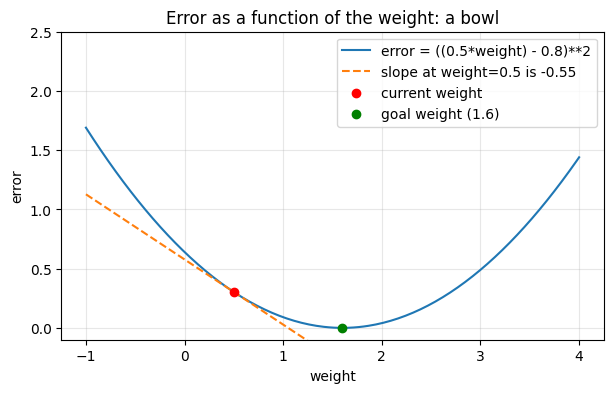

In [10]:
import numpy as np
import matplotlib.pyplot as plt

input, goal_pred = 0.5, 0.8
w = np.linspace(-1, 4, 200)
err = ((input * w) - goal_pred) ** 2

w0 = 0.5
e0 = ((input * w0) - goal_pred) ** 2
slope = 2 * input * ((input * w0) - goal_pred)      # slope of the error curve at w0
tangent = e0 + slope * (w - w0)

plt.figure(figsize=(7, 4))
plt.plot(w, err, label="error = ((0.5*weight) - 0.8)**2")
plt.plot(w, tangent, "--", label=f"slope at weight=0.5 is {slope:.2f}")
plt.scatter([w0], [e0], color="red", zorder=5, label="current weight")
plt.scatter([1.6], [0], color="green", zorder=5, label="goal weight (1.6)")
plt.ylim(-0.1, 2.5); plt.xlabel("weight"); plt.ylabel("error")
plt.title("Error as a function of the weight: a bowl"); plt.legend(); plt.grid(alpha=.3); plt.show()

At `weight = 0.5` the slope is negative (the curve falls to the right), so the weight must go **up** to reach the bottom at 1.6. The steeper the slope, the farther we probably are, so the slope supplies both *direction* and *amount*.

---
## Let's watch several steps of learning

With `input = 1.1`, the update overshoots a little, corrects back, and settles.

In [11]:
weight, goal_pred, input = (0.0, 0.8, 1.1)
path = [weight]

for iteration in range(4):
    print("-----\nWeight:" + str(weight))
    pred = input * weight
    error = (pred - goal_pred) ** 2
    delta = pred - goal_pred
    weight_delta = delta * input
    weight = weight - weight_delta
    path.append(weight)
    print("Error:" + str(error) + " Prediction:" + str(pred))
    print("Delta:" + str(delta) + " Weight Delta:" + str(weight_delta))

-----
Weight:0.0
Error:0.6400000000000001 Prediction:0.0
Delta:-0.8 Weight Delta:-0.8800000000000001
-----
Weight:0.8800000000000001
Error:0.02822400000000005 Prediction:0.9680000000000002
Delta:0.16800000000000015 Weight Delta:0.1848000000000002
-----
Weight:0.6951999999999999
Error:0.0012446784000000064 Prediction:0.76472
Delta:-0.03528000000000009 Weight Delta:-0.0388080000000001
-----
Weight:0.734008
Error:5.4890317439999896e-05 Prediction:0.8074088
Delta:0.007408799999999993 Weight Delta:0.008149679999999992


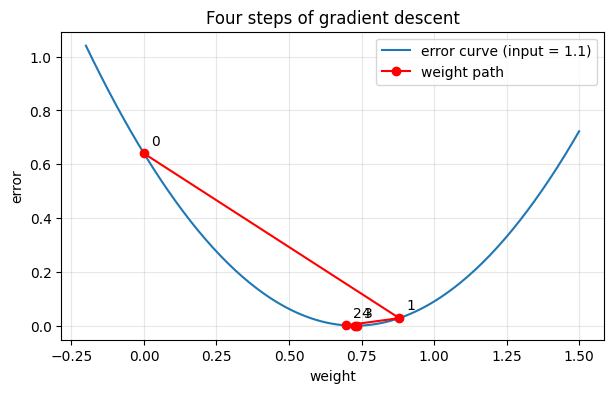

In [12]:
w = np.linspace(-0.2, 1.5, 200)
plt.figure(figsize=(7, 4))
plt.plot(w, ((1.1 * w) - 0.8) ** 2, label="error curve (input = 1.1)")
plt.plot(path, [((1.1 * p) - 0.8) ** 2 for p in path], "o-", color="red", label="weight path")
for i, p in enumerate(path):
    plt.annotate(str(i), (p, ((1.1 * p) - 0.8) ** 2), textcoords="offset points", xytext=(5, 6))
plt.xlabel("weight"); plt.ylabel("error"); plt.title("Four steps of gradient descent"); plt.legend(); plt.grid(alpha=.3); plt.show()

The first step lands past the bottom (weight 0.88 → prediction 0.968), the second swings back, and each swing is smaller than the last. The weight spirals in on 0.8 / 1.1 ≈ 0.727.

---
## Why does this work? What is weight_delta, really?

A **function** maps numbers in to numbers out, and each function has "moving parts" that control that mapping. Look at the error function:

`error = ((input * weight) - goal_pred) ** 2`

Which parts could we adjust to bring the error to zero?

| Part | Could we change it? | Why not |
|---|---|---|
| `goal_pred` | no | That would be lowering our standards, i.e. denying that we missed. |
| `input` | no | That would be changing reality until it matches our prediction. |
| the `** 2` and the arithmetic | no | That would break the error measure itself. |
| **`weight`** | **yes** | It is the only knob that changes *how the network predicts* without cheating. |

So learning = **adjusting weights so the error function falls to zero**. Everything we do to the `pred` calculation in later chapters is just a richer way of making that adjustment.

---
## Tunnel vision on one concept

The single idea to hold onto: **learning is adjusting the weight to reduce the error to 0.** What we really need is the *sensitivity* between the two variables: if the weight moves, how much and in what direction does the error move?

Hot and cold learning measured that sensitivity **experimentally** (like flipping unlabeled light switches to see which light turns on). But the formula `error = ((input * weight) - goal_pred) ** 2` already contains that relationship **exactly**. There is a mathematical tool to read it off directly.

---
## A box with rods poking out of it

Imagine a box with two rods sticking out: one blue, one red. You push the blue rod in by 1 inch and the red rod goes in by 2 inches; pull it out and the red follows. You've discovered `red = blue * 2`.

The answer to *"when I tug blue, how much does red move?"* is the **derivative**, here simply **2**. It has a sign too: positive means the rods move in the same direction, negative means opposite, and zero means red doesn't care what blue does.

In [13]:
def red_length(blue):
    return blue * 2

blue, h = 2.0, 1e-6
derivative = (red_length(blue + h) - red_length(blue)) / h     # "tug blue a tiny bit, see how much red moves"
print("derivative of red w.r.t. blue ~", round(derivative, 3))

derivative of red w.r.t. blue ~ 2.0


---
## Derivatives: take two

A second, equivalent view: **the derivative is the slope of the function's curve at a point.** For our error curve:

- Right of the bottom, the slope is positive; left of it, negative.
- The farther from the bottom, the steeper the slope.

So the **sign** of the slope tells you the direction, and its **steepness** hints at how far you are from the goal.

---
## What you really need to know

For *any* formula (even a monstrous one), you can pick any two variables and know how one reacts when you change the other. A neural network is "just" a pile of weights feeding one error function, so the derivative of the error with respect to each weight tells you how to change that weight.

**What you don't need:** a calculus course. You only need to understand *what* a derivative represents, i.e. the sensitivity between two variables. Specific derivative formulas can be looked up in a table.

---
## How to use a derivative to learn

> **`weight_delta` is your derivative.**

- `error` says *how much* you missed.
- The derivative says *how much each weight contributed to that miss*.

The slope always points away from the lowest point, so you move **against** it: raise the weight when the slope is negative, lower it when positive. That's why it's called gradient **descent**, like rolling downhill.

In [14]:
# Check: is weight_delta really the slope of the error curve?
input, goal_pred, weight, h = 0.5, 0.8, 0.5, 1e-6
error_fn = lambda w: ((input * w) - goal_pred) ** 2

weight_delta = (input * weight - goal_pred) * input                      # from the book
numeric_slope = (error_fn(weight + h) - error_fn(weight - h)) / (2 * h)  # measured on the curve

print("weight_delta (book)  :", round(weight_delta, 4))
print("measured slope       :", round(numeric_slope, 4))
print("ratio                :", round(numeric_slope / weight_delta, 4))

weight_delta (book)  : -0.275
measured slope       : -0.55
ratio                : 2.0


The measured slope is exactly **twice** `weight_delta`. The book drops that constant factor of 2 (it comes from squaring); it changes only the *scale* of the step, which `alpha` controls anyway. The sign and the proportionality are what matter.

---
## Look familiar?

Compare the loop from "Learning is just reducing error" with the derivative-based update: they are the same code. `weight_delta = delta * input` **is** the derivative, so gradient descent is simply "move the weight opposite its derivative".

---
## Breaking gradient descent

The book encourages you to try to break the algorithm. Let's make `input` larger, `input = 2`, keeping the goal at 0.8.

In [15]:
weight = 0.5
goal_pred = 0.8
input = 2

for iteration in range(20):
    pred = input * weight
    error = (pred - goal_pred) ** 2
    delta = pred - goal_pred
    weight_delta = input * delta
    weight = weight - weight_delta

    if iteration < 4 or iteration >= 17:
        print(f"iter {iteration:2d}  error = {error:.4g}  prediction = {pred:.4g}")

iter  0  error = 0.04  prediction = 1
iter  1  error = 0.36  prediction = 0.2
iter  2  error = 3.24  prediction = 2.6
iter  3  error = 29.16  prediction = -4.6
iter 17  error = 6.671e+14  prediction = -2.583e+07
iter 18  error = 6.004e+15  prediction = 7.748e+07
iter 19  error = 5.403e+16  prediction = -2.325e+08


The predictions swing between positive and negative, and each swing is *larger* than the last. After 20 iterations the error is around 10¹⁶.

---
## Visualizing the overcorrections

Each update lands on the opposite side of the bowl, *higher* up the wall than where it started. The curve for `input = 2` is much steeper and narrower, so the step is too big for it.

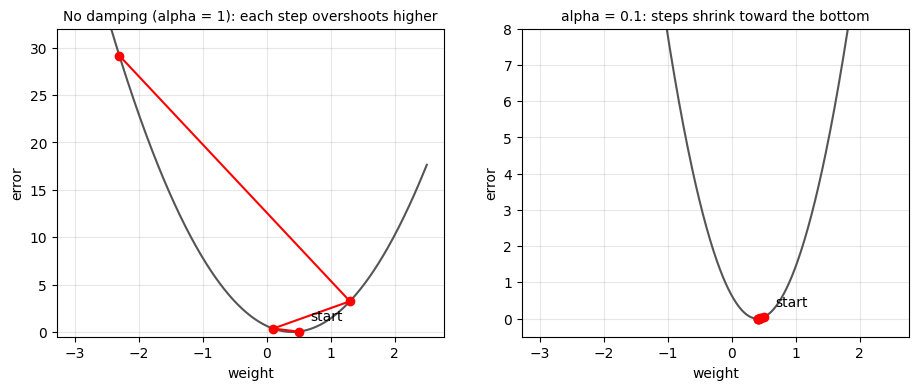

In [16]:
def run(alpha, input=2, goal=0.8, weight=0.5, iters=6):
    ws = [weight]
    for _ in range(iters):
        pred = input * weight
        weight = weight - alpha * input * (pred - goal)
        ws.append(weight)
    return ws

w = np.linspace(-3, 2.5, 400)
curve = ((2 * w) - 0.8) ** 2
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, alpha, iters, ymax, title in [(axes[0], 1.0, 3, 32, "No damping (alpha = 1): each step overshoots higher"),
                                      (axes[1], 0.1, 6, 8,  "alpha = 0.1: steps shrink toward the bottom")]:
    ws = run(alpha, iters=iters)
    ax.plot(w, curve, color="#555")
    ax.plot(ws, [((2 * p) - 0.8) ** 2 for p in ws], "o-", color="red")
    ax.annotate("start", (ws[0], ((2 * ws[0]) - 0.8) ** 2), textcoords="offset points", xytext=(8, 8))
    ax.set_ylim(-0.5, ymax); ax.set_xlabel("weight"); ax.set_ylabel("error"); ax.set_title(title, fontsize=10); ax.grid(alpha=.3)
plt.show()

---
## Divergence

Why did it blow up? The update is `weight = weight - (input * (pred - goal_pred))`. With a large `input`, the prediction is *very sensitive* to the weight (`pred = input * weight`), so the slope is steep and a small error produces a large step. If that step overshoots to a point where the error is even larger, the next step is bigger still. Round after round, the error grows. This is **divergence**.

---
## Introducing alpha

The cure is to multiply every update by a small number **alpha** between 0 and 1. The symptom we're treating is overshooting, so we simply take smaller steps.

- Too small: learning is slow but safe.
- Too large: it overshoots and may diverge.
- In practice, alpha is found by **trying orders of magnitude** (10, 1, 0.1, 0.01, 0.001, 0.0001) and watching whether the error falls, stalls, or rises.

---
## Alpha in code

The update changes from `weight = weight - derivative` to:

`weight = weight - (alpha * derivative)`

In [17]:
weight = 0.5
goal_pred = 0.8
input = 2
alpha = 0.1

for iteration in range(20):
    pred = input * weight
    error = (pred - goal_pred) ** 2
    derivative = input * (pred - goal_pred)
    weight = weight - (alpha * derivative)

    if iteration < 3 or iteration >= 17:
        print("Error:" + str(error) + " Prediction:" + str(pred))

Error:0.03999999999999998 Prediction:1.0
Error:0.0144 Prediction:0.92
Error:0.005183999999999993 Prediction:0.872
Error:1.1460471998340758e-09 Prediction:0.8000338533188895
Error:4.125769919393652e-10 Prediction:0.8000203119913337
Error:1.485277170987127e-10 Prediction:0.8000121871948003


Same input that exploded before now converges smoothly to 0.8. Next, let's answer the book's question: *what happens with a tiny, huge, or negative alpha?*

alpha =  0.001: final error = 3.435e-02
alpha =    0.1: final error = 1.485e-10
alpha =   0.25: final error = 0.000e+00
alpha =    0.3: final error = 1.089e-28
alpha =    0.6: final error = 1.429e+04
alpha =   -0.1: final error = 1.429e+04


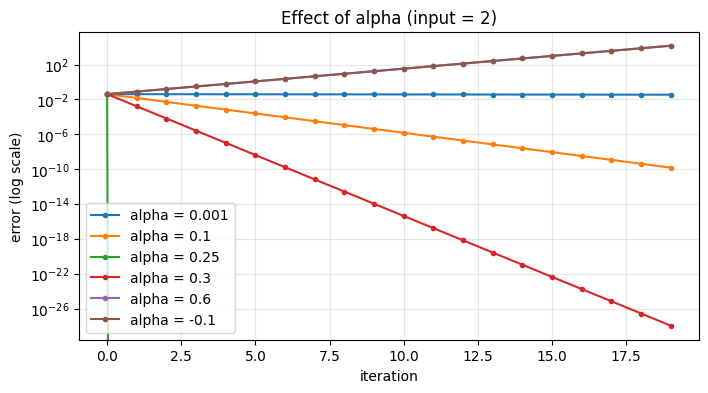

In [18]:
def train(alpha, input=2, goal_pred=0.8, weight=0.5, iters=20):
    errs = []
    for _ in range(iters):
        pred = input * weight
        errs.append((pred - goal_pred) ** 2)
        weight = weight - alpha * input * (pred - goal_pred)
    return errs

fig, ax = plt.subplots(figsize=(8, 4))
for a in [0.001, 0.1, 0.25, 0.3, 0.6, -0.1]:
    e = train(a)
    ax.plot(e, marker="o", ms=3, label=f"alpha = {a}")
    print(f"alpha = {a:>6}: final error = {e[-1]:.3e}")
ax.set_yscale("log"); ax.set_xlabel("iteration"); ax.set_ylabel("error (log scale)")
ax.set_title("Effect of alpha (input = 2)"); ax.legend(); ax.grid(alpha=.3); plt.show()

| alpha | Behaviour for `input = 2` |
|---|---|
| 0.001 | Safe but very slow (error barely drops in 20 steps) |
| 0.1 | Smooth, fast convergence |
| 0.25 | Reaches the goal almost immediately (here `alpha × input² = 1`, a perfect step) |
| 0.3 | Overshoots and swings across the goal, but the swings shrink |
| 0.6 | Swings **grow**: diverges |
| −0.1 | A *negative* alpha climbs the bowl instead of descending it: error explodes |

For this setup a step is stable when `0 < alpha × input² < 2` (so `alpha < 0.5` at `input = 2`).

In [19]:
# Bonus: how many predictions does each method need? (stop when error < 1e-6)
def predictions_needed(method, tol=1e-6, max_iter=100000):
    weight, input, goal = 0.5, 0.5, 0.8
    for it in range(max_iter):
        pred = input * weight
        if (pred - goal) ** 2 < tol:
            return it
        if method == "hot_cold":
            up   = (goal - input * (weight + 0.001)) ** 2
            down = (goal - input * (weight - 0.001)) ** 2
            weight += -0.001 if down < up else 0.001
        else:
            weight -= input * (pred - goal)
    return None

hc, gd = predictions_needed("hot_cold"), predictions_needed("gradient_descent")
print(f"hot and cold     : {hc} iterations  (~{3 * hc} predictions, 3 per iteration)")
print(f"gradient descent : {gd} iterations  (~{gd} predictions, 1 per iteration)")

hot and cold     : 1099 iterations  (~3297 predictions, 3 per iteration)
gradient descent : 22 iterations  (~22 predictions, 1 per iteration)


---
## Memorizing

The author's main study tip: **rebuild the final gradient-descent-with-alpha code from memory**. Later chapters will say things like "add your alpha to the weight update" and expect you to recognise it instantly.

A scaffold to practise with is below. Fill in the blanks (`...`) without scrolling up, then compare with the *Alpha in code* cell.

In [20]:
# Exercise: complete the blanks, then run.  (Answer: see "Alpha in code")
weight, goal_pred, input, alpha = 0.5, 0.8, 2, 0.1

# for iteration in range(20):
#     pred  = ...
#     error = ...
#     derivative = ...
#     weight = ...
#     print(error, pred)

---
## Summary

- **Compare** with squared error (positive, emphasises big misses); **learn** by attributing the error to weights.
- **Hot and cold learning** wiggles the weight: simple, but slow (3 predictions per step) and its step size is a guess.
- **Gradient descent** computes direction *and* amount in one line: `weight_delta = input * (pred - goal_pred)`, with built-in *stopping, negative reversal, and scaling*.
- `weight_delta` is the **derivative** of the error with respect to the weight, the slope of the error "bowl". Move the weight *against* the slope.
- Large inputs can cause **divergence**; **alpha** scales the update down to prevent it.
- Next chapter: the same recipe for networks with **many weights** at once.